# <div align="center"><span style="color:red">Assignment 4 : Semantic Segmentation with CNNs </span></div>

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
import numpy as np

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


# Question 1:

## a :

In [3]:
data_path = "./data"
train_transform = transforms.ToTensor()

train_dataset = torchvision.datasets.VOCSegmentation(
    root=data_path,
    year="2007",
    image_set="train",
    download=False,
    transform=train_transform
)

## b:

In [4]:
image0, mask0 = train_dataset[0]
mask0 = np.array(mask0)

print(f"the total number of training samples : {len(train_dataset)}")
print(f"the shape of first image : {image0.shape}")
print(f"the shape of first image's mask : {mask0.shape}")

the total number of training samples : 209
the shape of first image : torch.Size([3, 281, 500])
the shape of first image's mask : (281, 500)


# Question 2: 

## a:

In [5]:
image_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

mask_transform = transforms.Compose([
    transforms.Resize((128, 128), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.PILToTensor()
])

In [6]:
class dataset(Dataset):
    def __init__(self):
        self.train_dataset = torchvision.datasets.VOCSegmentation(
        root=data_path,
        year="2007",
        image_set="train",
        download=False
        )
    
    def __len__(self):
        return len(self.train_dataset)
    
    def __getitem__(self, index):
        image, mask = self.train_dataset[index]
        image = image_transform(image)
        mask = mask_transform(mask).squeeze(0).long()
        return image, mask

In [7]:
train_dataset = dataset()

## b:

In [8]:
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

## c:

In [9]:
image0, mask0 = train_dataset[0]

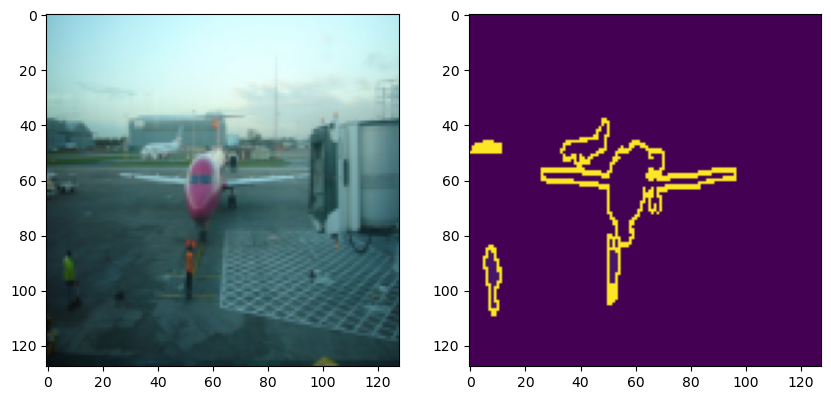

In [10]:
plt.figure(figsize = (10, 10))

plt.subplot(1, 2, 1)
plt.imshow(image0.permute(1, 2, 0))

plt.subplot(1, 2, 2)
plt.imshow(mask0)

plt.show()

# Question 4:

In [11]:
class ConvLayer(nn.Module):
    def __init__(self, in_channels, out_channels, stride):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels=in_channels, out_channels=out_channels, kernel_size=3, padding=1, stride=stride),
            nn.BatchNorm2d(out_channels),
            nn.ReLU()
        )

    def forward(self, x):
        x = self.block(x)
        return x

In [12]:
class ConvTranspose(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.ConvTranspose2d(in_channels=in_channels, out_channels=out_channels, kernel_size=2, stride=2),
            nn.BatchNorm2d(out_channels),
            nn.ReLU()
        )

    def forward(self, x):
        x = self.block(x)
        return x

In [13]:
class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.convblock = nn.Sequential(
            ConvLayer(3, 64, 2),

            ConvLayer(64, 128, 1),
            ConvLayer(128, 128, 2),

            ConvLayer(128, 256, 1),
            ConvLayer(256, 256, 1),
            ConvLayer(256, 256, 2),

            ConvLayer(256, 512, 1),
            ConvLayer(512, 512, 1),

            ConvTranspose(512, 256),
            ConvLayer(256, 256, 1),
            ConvLayer(256, 256, 1),

            ConvTranspose(256, 128),
            ConvLayer(128, 128, 1),

            ConvTranspose(128, 64),

            nn.Conv2d(in_channels=64, out_channels=21, kernel_size=1)
        )

    def forward(self, x):
        x = self.convblock(x)
        return x

# Question 5:

## a : 

In [14]:
loss_function = nn.CrossEntropyLoss(ignore_index=255)

## c :

In [15]:
model = ConvNet()
learning_rate = 0.001
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Question 6:

## a : 

In [16]:
def training_loop(model, train_loader, loss_function, optimizer, num_epochs , device):
    model.to(device)

    epoch_loss = []

    print("--- Training Started ---")

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        for image, mask in train_loader:
            image, mask = image.to(device), mask.to(device)

            optimizer.zero_grad()
            predictions = model(image)
            loss = loss_function(predictions, mask)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * len(mask)
        
        epoch_loss.append(running_loss / len(train_loader.dataset))
        print(f"Epoch [{epoch+1}/{num_epochs}] - Loss: {epoch_loss[epoch]:.4f}")

    return model, epoch_loss

## b : 

In [35]:
model, loss = training_loop(
    model=model,
    train_loader=train_loader, 
    loss_function=loss_function, 
    optimizer=optimizer,
    num_epochs=200, 
    device=device
)

--- Training Started ---
Epoch [1/200] - Loss: 0.7090
Epoch [2/200] - Loss: 0.6923
Epoch [3/200] - Loss: 0.6967
Epoch [4/200] - Loss: 0.7054
Epoch [5/200] - Loss: 0.6676
Epoch [6/200] - Loss: 0.6419
Epoch [7/200] - Loss: 0.6587
Epoch [8/200] - Loss: 0.6452
Epoch [9/200] - Loss: 0.6342
Epoch [10/200] - Loss: 0.7576
Epoch [11/200] - Loss: 0.7411
Epoch [12/200] - Loss: 0.6934
Epoch [13/200] - Loss: 0.6428
Epoch [14/200] - Loss: 0.6490
Epoch [15/200] - Loss: 0.6317
Epoch [16/200] - Loss: 0.6180
Epoch [17/200] - Loss: 0.5842
Epoch [18/200] - Loss: 0.6104
Epoch [19/200] - Loss: 0.6084
Epoch [20/200] - Loss: 0.6224
Epoch [21/200] - Loss: 0.5757
Epoch [22/200] - Loss: 0.5892
Epoch [23/200] - Loss: 0.5467
Epoch [24/200] - Loss: 0.5741
Epoch [25/200] - Loss: 0.5407
Epoch [26/200] - Loss: 0.5205
Epoch [27/200] - Loss: 0.5201
Epoch [28/200] - Loss: 0.5196
Epoch [29/200] - Loss: 0.5725
Epoch [30/200] - Loss: 0.6128
Epoch [31/200] - Loss: 0.5617
Epoch [32/200] - Loss: 0.6058
Epoch [33/200] - Loss: 0

# Question 7 :

## a : 

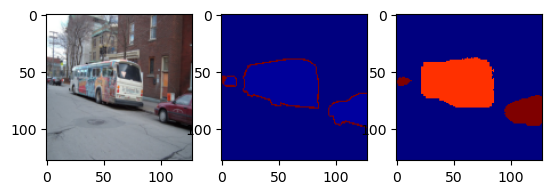

In [41]:
model.to(torch.device("cpu"))
model.eval()
with torch.no_grad():
    for image, mask in train_loader:
        image, mask = image.to(torch.device("cpu")), mask.to(torch.device("cpu"))
        prediction = model(image)
        prediction = torch.argmax(prediction, dim=1)   # (B, H, W)


        plt.subplot(1, 3, 1)
        plt.imshow(image[0].permute(1, 2, 0))
        plt.subplot(1, 3, 2)
        plt.imshow(mask[0], cmap="jet")
        plt.subplot(1, 3, 3)
        plt.imshow(prediction[0], cmap="jet")

        break


